# Building Energy Analyzer - Analysis Notebook

This notebook explains the analysis behind the project. It uses the same functions as the application
(`module1_energy_calculator.py` and `module2_analysis.py`), so the results here match the menu in `main.py`.

**Data:** 8 rooms in 2 buildings (`data/rooms.csv`) and daily readings from 1 Aug to 30 Sep 2026 (`data/readings.csv`).

In [1]:
import pandas as pd, numpy as np
import module2_analysis as m2
from module1_energy_calculator import RoomManager

PRICE_PER_KWH = 0.15      # currency units per kWh (user-entered in the app)
AC_REDUCTION = 20         # percent (user-selected in the app)

rooms = pd.read_csv("data/rooms.csv")
raw = m2.load_readings("data/readings.csv")
print(rooms.to_string(index=False))
print("\nRaw readings:", raw.shape, "| missing values:", int(raw.actual_kwh.isna().sum()),
      "| duplicate rows:", int(raw.duplicated().sum()))

room_id      room_name       building  area_m2  lighting_kw  ac_kw  equipment_kw  hours_per_day
    R01    Open Office    Admin Block      120          1.8    9.0           3.5             10
    R02   Meeting Room    Admin Block       35          0.5    3.5           0.8              6
    R03 Manager Office    Admin Block       28          0.3    2.8           0.6              8
    R04    Server Room    Admin Block       20          0.2    5.0           8.0             24
    R05   Lecture Hall Academic Block      150          2.4   12.0           2.0              8
    R06   Computer Lab Academic Block       80          1.2    7.0           6.5              9
    R07        Library Academic Block      200          3.0   14.0           1.5             10
    R08      Cafeteria Academic Block       90          1.0    6.0           5.0              7

Raw readings: (490, 3) | missing values: 3 | duplicate rows: 2


## 1. Estimated consumption (Module 1)
Daily energy = (lighting + AC + equipment kW) x operating hours. Consumption per m2 = daily energy / area.

In [2]:
mgr = RoomManager()
loaded, errors = mgr.load_csv("data/rooms.csv")
print(f"{'Room':<15}{'kWh/day':>10}{'kWh/day/m2':>12}")
for rid, name, kwh, per_m2 in mgr.summary():
    print(f"{name:<15}{kwh:>10.1f}{per_m2:>12.3f}")
print("\nTotal estimated:", round(mgr.total_consumption(), 1), "kWh/day")

Room              kWh/day  kWh/day/m2
Open Office         143.0       1.192
Meeting Room         28.8       0.823
Manager Office       29.6       1.057
Server Room         316.8      15.840
Lecture Hall        131.2       0.875
Computer Lab        132.3       1.654
Library             185.0       0.925
Cafeteria            84.0       0.933

Total estimated: 1050.7 kWh/day


The Server Room has the highest estimated consumption per m2 by far (it runs 24 hours with 8 kW of equipment).

## 2. Cleaning and merging (Module 2)
Steps: parse dates and numbers, remove duplicate rows, treat negative values as missing, fill missing values
with the median of the **same room and same day type** (weekday/weekend), then merge with the room table.
Filling with the overall room median would be wrong here because weekend consumption is much lower than weekday consumption in most rooms.

In [3]:
clean, report = m2.clean_readings(raw)
for k, v in report.items():
    print(f"{k}: {v}")
merged = m2.merge_with_rooms(clean, rooms)
print("\nMerged shape:", merged.shape)
print("Readings per day:", merged.groupby("date").size().unique())

rows_before: 490
invalid_dates_removed: 0
duplicates_removed: 2
negative_values_set_missing: 0
missing_values_filled: 3
rows_after: 488

Merged shape: (488, 12)
Readings per day: [8]


## 3. Consumption and cost per room, building and month

In [4]:
df = m2.add_cost(merged, PRICE_PER_KWH)
print("BY ROOM");     print(m2.by_room(df).to_string(index=False))
print("\nBY BUILDING"); print(m2.by_building(df).to_string(index=False))
print("\nBY MONTH");    print(m2.by_month(df).to_string(index=False))

BY ROOM
room_id      room_name       building  total_kwh  avg_daily_kwh  total_cost
    R01    Open Office    Admin Block    5540.51          90.83      831.08
    R02   Meeting Room    Admin Block    1094.76          17.95      164.21
    R03 Manager Office    Admin Block    1109.19          18.18      166.38
    R04    Server Room    Admin Block   14569.05         238.84     2185.36
    R05   Lecture Hall Academic Block    4989.56          81.80      748.43
    R06   Computer Lab Academic Block    5254.92          86.15      788.24
    R07        Library Academic Block    7726.45         126.66     1158.97
    R08      Cafeteria Academic Block    3478.52          57.02      521.78

BY BUILDING
      building  total_kwh  avg_daily_kwh  total_cost
Academic Block   21449.46          87.91     3217.42
   Admin Block   22313.51          91.45     3347.03

BY MONTH
  month  total_kwh  avg_daily_kwh  total_cost
2026-08   23613.06          95.21     3541.96
2026-09   20149.90          83.96 

## 4. Estimated vs actual consumption
The actual average is lower than the estimate from nameplate power in every room. This is expected: lighting, AC and equipment rarely all run at full power at the same time.

In [5]:
est = (rooms.lighting_kw + rooms.ac_kw + rooms.equipment_kw) * rooms.hours_per_day
cmp_ = m2.by_room(df)[["room_id", "room_name", "avg_daily_kwh"]].copy()
cmp_["estimated_kwh"] = est.to_numpy()
cmp_["actual_vs_estimated_%"] = (cmp_.avg_daily_kwh / cmp_.estimated_kwh * 100).round(1)
print(cmp_.round(2).to_string(index=False))
print()
print("Average daily kWh per room, weekday vs weekend:")
print(df.groupby(["room_name", "is_weekend"]).actual_kwh.mean().unstack().round(1).rename(columns={False: "weekday", True: "weekend"}))

room_id      room_name  avg_daily_kwh  estimated_kwh  actual_vs_estimated_%
    R01    Open Office          90.83          143.0                   63.5
    R02   Meeting Room          17.95           28.8                   62.3
    R03 Manager Office          18.18           29.6                   61.4
    R04    Server Room         238.84          316.8                   75.4
    R05   Lecture Hall          81.80          131.2                   62.3
    R06   Computer Lab          86.15          132.3                   65.1
    R07        Library         126.66          185.0                   68.5
    R08      Cafeteria          57.02           84.0                   67.9

Average daily kWh per room, weekday vs weekend:
is_weekend      weekday  weekend
room_name                       
Cafeteria          62.6     43.6
Computer Lab       99.3     54.7
Lecture Hall       94.3     52.0
Library           131.9    114.0
Manager Office     20.9     11.7
Meeting Room       20.7     11.4
Ope

## 5. AC reduction scenario (NumPy)
Only AC power is reduced. Operating hours, lighting and equipment stay unchanged. NumPy arrays are used so the calculation is done for all rooms at once.

In [6]:
sc = m2.ac_reduction_scenario(rooms, AC_REDUCTION)
print(sc.to_string(index=False))
tot_b, tot_a = sc.est_kwh_before.sum(), sc.est_kwh_after.sum()
print(f"\nTotal before: {tot_b:.1f} kWh/day | after: {tot_a:.1f} kWh/day | saving: {tot_b - tot_a:.1f} kWh/day ({(tot_b - tot_a) / tot_b * 100:.1f}%)")

room_id      room_name       building  ac_kw_before  ac_kw_after  est_kwh_before  est_kwh_after  saving_kwh  saving_percent
    R01    Open Office    Admin Block           9.0         7.20           143.0         125.00       18.00           12.59
    R02   Meeting Room    Admin Block           3.5         2.80            28.8          24.60        4.20           14.58
    R03 Manager Office    Admin Block           2.8         2.24            29.6          25.12        4.48           15.14
    R04    Server Room    Admin Block           5.0         4.00           316.8         292.80       24.00            7.58
    R05   Lecture Hall Academic Block          12.0         9.60           131.2         112.00       19.20           14.63
    R06   Computer Lab Academic Block           7.0         5.60           132.3         119.70       12.60            9.52
    R07        Library Academic Block          14.0        11.20           185.0         157.00       28.00           15.14
    R08 

Rooms where AC is a bigger share of total power (Library, Manager Office, Lecture Hall) save the most in percentage terms.
The Server Room saves the least in percentage because most of its load is equipment, not AC.

## 6. Charts

Saved:
  charts/line_daily_consumption.png
  charts/bar_cost_per_room.png
  charts/scatter_area_vs_consumption.png
  charts/hist_daily_readings.png


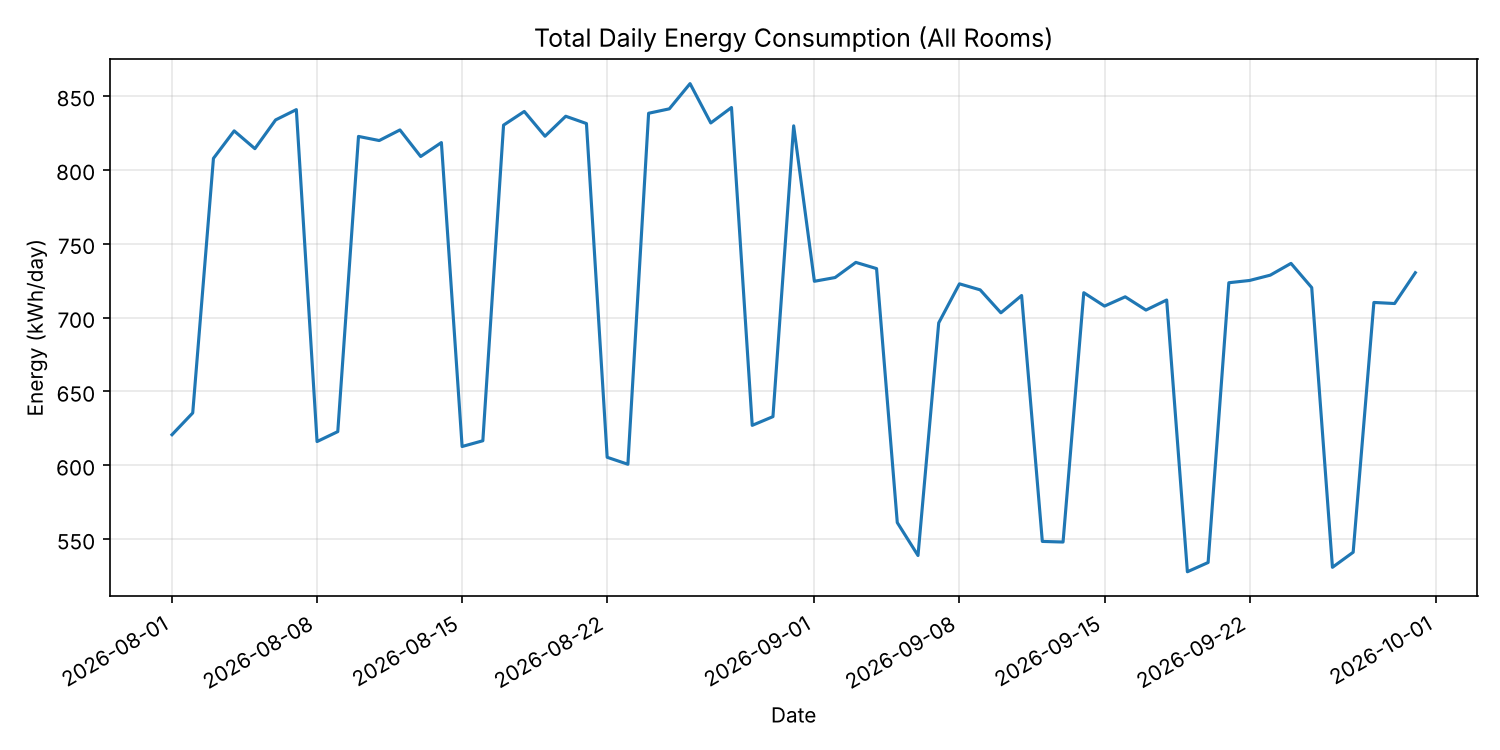

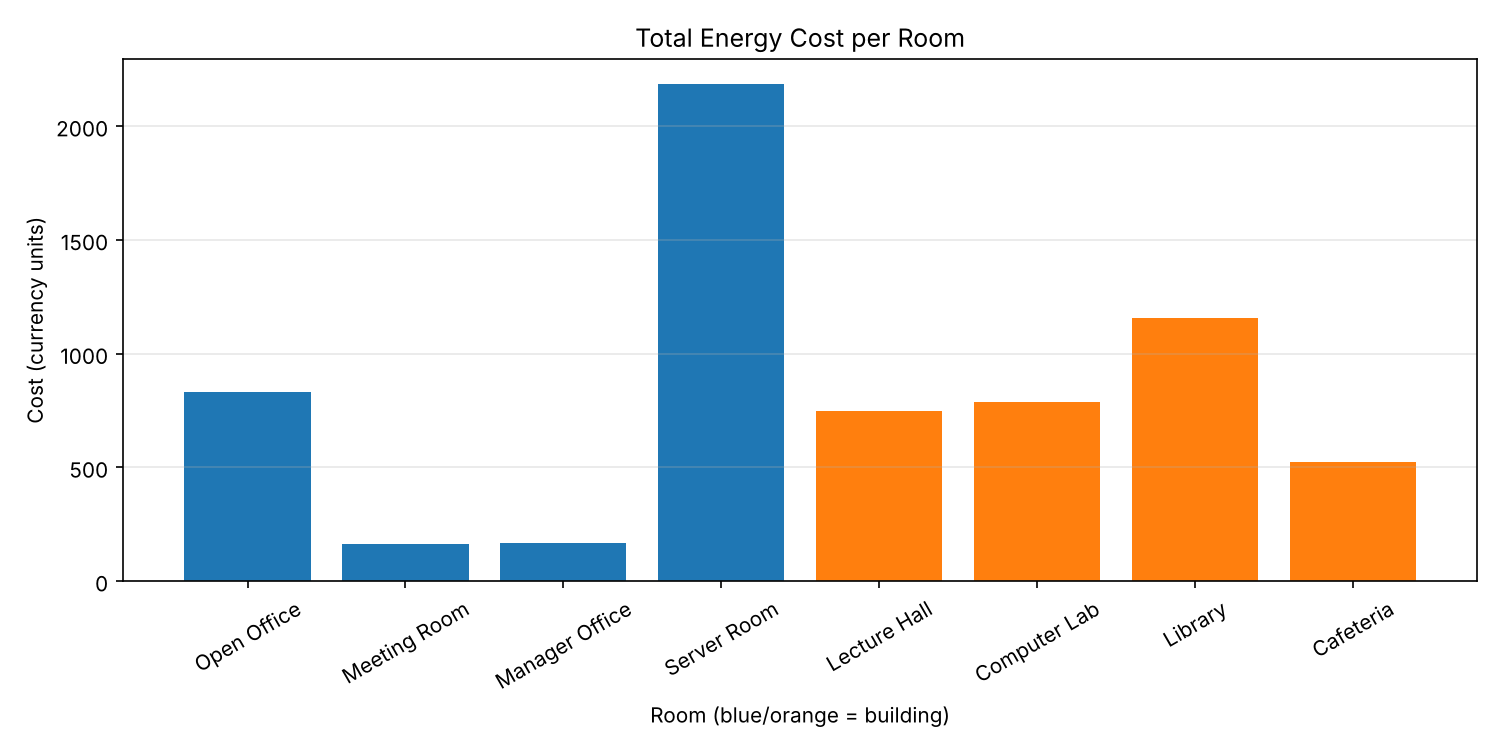

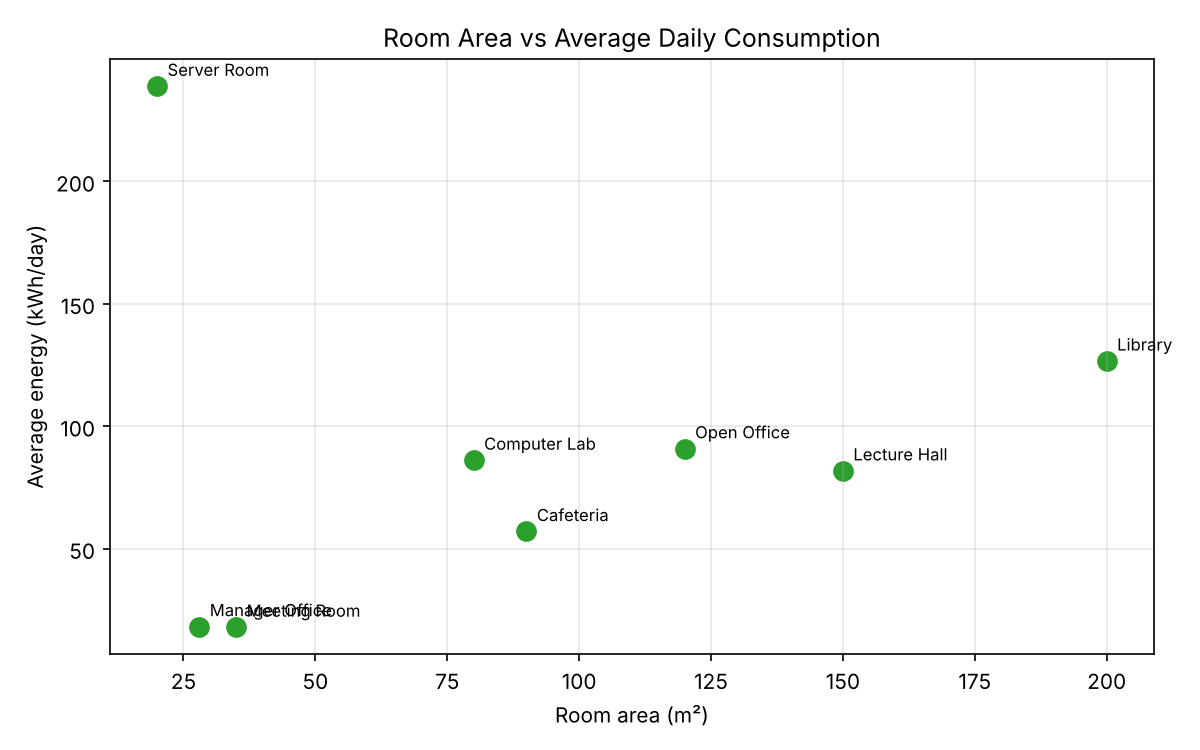

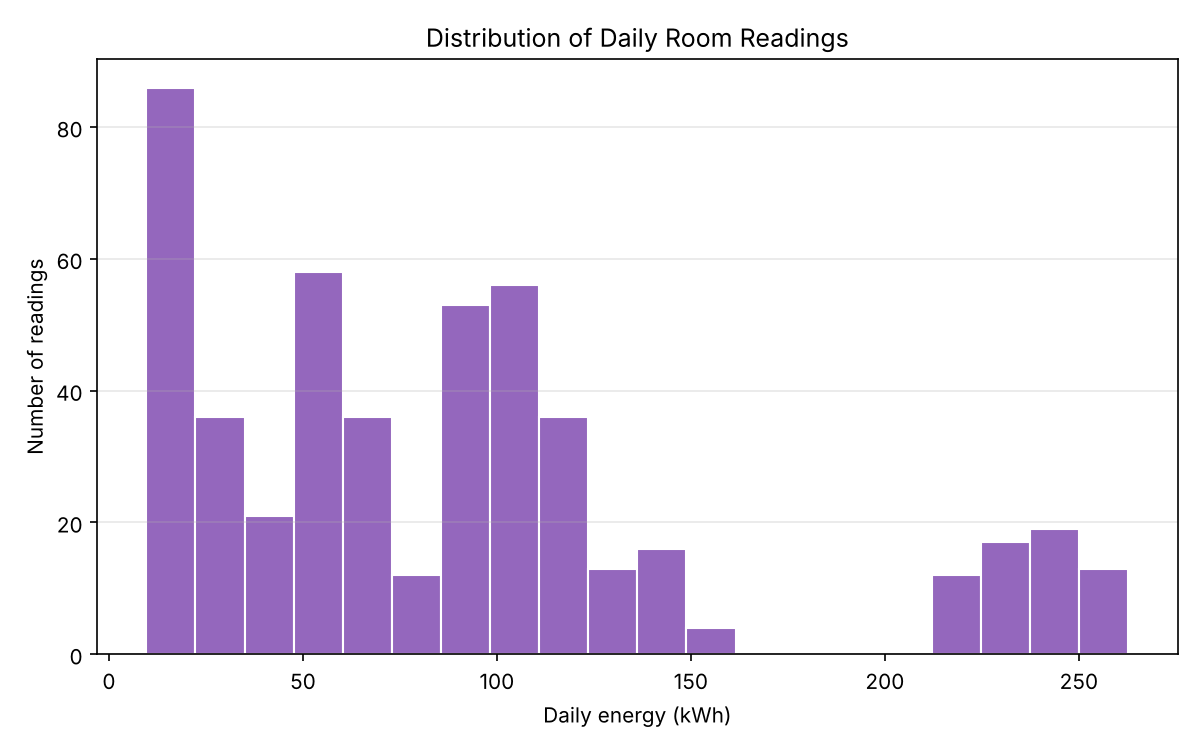

In [7]:
paths = m2.make_charts(df, "charts")
print("Saved:", *paths, sep="\n  ")

## 7. Conclusions
- The **Server Room** uses about **33%** of all measured energy (it runs flat at ~239 kWh/day, weekdays and weekends alike), so it is the first place to look for savings.
- **August used more energy than September** (about 23,600 kWh vs 20,150 kWh), which fits higher cooling demand in the hotter month.
- Most rooms use **much less on weekends** (e.g. Open Office 105 kWh on weekdays vs 58 kWh on weekends). The Server Room does not change at all, and the Library changes only slightly.
- Actual consumption is about **61-75%** of the nameplate estimate, so the estimate is a safe upper bound rather than a prediction.
- A **20% AC power reduction** would save about **119 kWh/day (11.3%)** of the estimated total.